Assessment 2 (City Water Network Monitoring and Leak Detection)

In [0]:
dbutils.widgets.text("catalog", "workspace")
dbutils.widgets.text("schema", "default")
dbutils.widgets.text("volume", "assessment_files")
catalog = dbutils.widgets.get("catalog"); schema = dbutils.widgets.get("schema"); volume = dbutils.widgets.get("volume")
spark.sql(f"USE CATALOG `{catalog}`")
spark.sql(f"USE SCHEMA `{schema}`")
from pyspark.sql import functions as F, Window
from delta.tables import DeltaTable

Section A

In [0]:
%sql
-- Q1 e
DESCRIBE TABLE water_meter_readings_source;

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:

%sql
SELECT COUNT(*) AS total_rows FROM water_meter_readings_source;

total_rows
157


In [0]:
%sql
select reading_id, meter_id, zone_id, reading_time, consumption_liters from water_meter_readings_source
where reading_status = 'Valid';

In [0]:
%sql
select * from water_meter_readings_source where pressure_bar < 2.5 order by pressure_bar asc;

In [0]:
%sql
select * from water_meter_readings_source where flow_lpm between 20 and 50 and source_system in ('Gateway', 'SmartMeter');

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


In [0]:
%sql
select reading_status, count(*) as readings from water_meter_readings_source group by reading_status order by readings desc;

reading_status,readings
Valid,137
Suspect,11
Rejected,9


Section B

In [0]:
%sql
select z.zone_name, z.district, r.meter_id, r.consumption_liters from water_meter_readings_source r
join water_zones z on r.zone_id = z.zone_id;

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


In [0]:
%sql
select r.* from water_meter_readings_source r left anti join water_zones z on r.zone_id = z.zone_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
%sql
select z.* from water_zones z left anti join water_meter_readings_source r on r.zone_id = z.zone_id;

zone_id,zone_name,city,district,zone_type,daily_capacity_liters,active,commissioned_on
W11,New Development,Hyderabad,West,Mixed,125000,false,2021-03-15


In [0]:
%sql
select z.zone_id, z.zone_name,SUM(r.consumption_liters) as total_valid_consumption,
       round(avg(r.pressure_bar),2) as avg_pressure_bar, count(*) as reading_count
from water_meter_readings_source r join water_zones z on r.zone_id = z.zone_id
where r.reading_status = 'Valid' and r.consumption_liters > 0
group by z.zone_id, z.zone_name
order by total_valid_consumption desc;

zone_id,zone_name,total_valid_consumption,avg_pressure_bar,reading_count
W03,Market District,35665,3.02,13
W08,Transit Hub,33689,2.87,14
W05,University Quarter,28717,3.63,14
W10,South Extension,27808,3.72,14
W07,Garden Colony,25104,3.57,13
W02,Hill View,24120,3.31,13
W01,Old City,23107,3.42,13
W09,Riverfront,20894,3.55,13
W04,Lake Side,20781,3.24,14
W06,Industrial Estate,20212,3.16,13


In [0]:
%sql
with meter_tot as (select z.district, r.meter_id, SUM(r.consumption_liters) as total_consumption
  from water_meter_readings_source r join water_zones z on r.zone_id = z.zone_id
  where r.reading_status = 'Valid' and r.consumption_liters > 0
  group by z.district, r.meter_id)
select *, RANK() over (partition by district order by total_consumption desc) as district_rank
from meter_tot order by district, district_rank;

district,meter_id,total_consumption,district_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


Section C - PySpark Dataframes

In [0]:
readings = spark.table("water_meter_readings_source")
zones = spark.table("water_zones")
readings.printSchema(); zones.printSchema()

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



In [0]:
(readings.select("reading_id", "meter_id", "zone_id", "flow_lpm", "pressure_bar")
         .filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60))
         .orderBy(F.col("flow_lpm").desc())).display()

reading_id,meter_id,zone_id,flow_lpm,pressure_bar
1110,M020,W10,84.0,4.45
1106,M016,W06,83.9,4.69
1083,M023,W03,83.9,2.68
1010,M010,W10,81.3,2.38
1013,M013,W03,80.7,3.8
1078,M018,W08,80.7,2.28
1093,M003,W03,80.4,4.35
1031,M001,W01,80.1,2.38
1123,M003,W03,79.7,2.11
1044,M014,W04,79.3,1.95


In [0]:
readings_cat = readings.withColumn(
    "flow_category",
    F.when(F.col("flow_lpm").isNull(), "Unknown")
     .when(F.col("flow_lpm") >= 60, "High")
     .when(F.col("flow_lpm") >= 30, "Medium")
     .otherwise("Low"))
readings_cat.groupBy("flow_category").count().display()

flow_category,count
Medium,68
Low,44
High,45


In [0]:
avg_flow=readings.join(zones, "zone_id").groupBy("zone_type").agg(F.round(F.avg("flow_lpm"), 2).alias("avg_flow_lpm")).orderBy(F.desc("avg_flow_lpm"))
avg_flow.display()

zone_type,avg_flow_lpm
Commercial,56.1
Institutional,49.33
Residential,45.16
Industrial,43.14
Mixed,38.17


In [0]:
top3=readings.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))\
     .join(zones, "zone_id").groupBy("zone_id", "zone_name").agg(F.sum("consumption_liters").alias("total_consumption"),
     F.round(F.avg("pressure_bar"), 2).alias("avg_pressure")).orderBy(F.desc("total_consumption")).limit(3)
top3.display()

zone_id,zone_name,total_consumption,avg_pressure
W03,Market District,35665,3.02
W08,Transit Hub,33689,2.87
W05,University Quarter,28717,3.63


Section D

In [0]:
%sql
select * from water_meter_readings_source where reading_id IN (SELECT reading_id from water_meter_readings_source group by reading_id having count(*) > 1) order by reading_id, reading_time;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16T13:00:00.000Z,36.0,3.2,0.8,1300,Valid,Gateway


In [0]:
%sql
select sum(case when pressure_bar  is null then 1 else 0 end) as missing_pressure,
       sum(case when source_system is null then 1 else 0 end) as missing_source_system
from water_meter_readings_source;
select * from water_meter_readings_source where pressure_bar is null or source_system is null;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1153,M020,W10,2026-10-16T10:00:00.000Z,31.4,null,0.71,1020,Valid,Gateway
1155,M006,W06,2026-10-16T12:00:00.000Z,44.0,2.9,2.95,1560,Suspect,null


In [0]:
%sql
select * from water_meter_readings_source where flow_lpm < 0 or consumption_liters <= 0 or zone_id is null;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1151,M004,W04,2026-10-16T08:00:00.000Z,-12.5,2.8,0.62,500,Suspect,Gateway
1152,M015,W05,2026-10-16T09:00:00.000Z,22.0,2.1,0.5,0,Valid,SmartMeter
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
%sql
create or replace table water_readings_clean as
select * except (rn) from (
  select *, row_number() over (partition by reading_id
                               order by reading_time desc, source_system asc nulls last) as rn
  from water_meter_readings_source
  where reading_status = 'Valid'
    and flow_lpm > 0 and consumption_liters > 0
    and pressure_bar > 0 and zone_id is not null)
where rn = 1;
select count(*) as clean_rows, count(distinct reading_id) as distinct_ids from water_readings_clean;  -- expect 133 = 133



clean_rows,distinct_ids
133,133


In [0]:
%sql
with hp as (
  select zone_id, count(*) as high_priority_requests
  from water_service_requests where priority = 'High' group by zone_id),
pr as (
  select zone_id, round(avg(pressure_bar),2) as avg_pressure
  from water_readings_clean group by zone_id)
select pr.zone_id, z.zone_name, coalesce(hp.high_priority_requests,0) as high_priority_requests, pr.avg_pressure,
       case when hp.zone_id is not null then 'has high request' else 'no high request' end as grp
from pr join water_zones z using (zone_id) left join hp using (zone_id)
order by high_priority_requests desc, avg_pressure;

zone_id,zone_name,high_priority_requests,avg_pressure,grp
W02,Hill View,2,3.31,has high request
W01,Old City,2,3.42,has high request
W08,Transit Hub,1,2.87,has high request
W03,Market District,1,3.02,has high request
W06,Industrial Estate,1,3.16,has high request
W04,Lake Side,1,3.34,has high request
W09,Riverfront,1,3.55,has high request
W07,Garden Colony,1,3.57,has high request
W05,University Quarter,1,3.63,has high request
W10,South Extension,1,3.72,has high request


Section E

In [0]:
%sql
create or replace table water_readings_work_copy as select * from water_meter_readings_work;
select count(*) from water_readings_work_copy;

count(*)
157


In [0]:
%sql
INSERT INTO water_readings_work_copy VALUES
 (9001,'M001','W01',TIMESTAMP'2026-10-25 08:00:00',41.5,3.4,0.70,2400,'Valid','Gateway'),
 (9002,'M002','W02',TIMESTAMP'2026-10-25 09:00:00',33.2,3.1,0.55,1800,'Valid','SmartMeter');
SELECT * FROM water_readings_work_copy WHERE reading_id IN (9001, 9002);

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
9001,M001,W01,2026-10-25T08:00:00.000Z,41.5,3.4,0.7,2400,Valid,Gateway
9002,M002,W02,2026-10-25T09:00:00.000Z,33.2,3.1,0.55,1800,Valid,SmartMeter


In [0]:
%sql
update water_readings_work_copy set reading_status = 'Rejected' where reading_id = 1005;
select reading_id, reading_status from water_readings_work_copy where reading_id = 1005;

reading_id,reading_status
1005,Rejected


In [0]:
%sql
select 'before' as stage, count(*) as n from water_readings_work_copy;
delete from water_readings_work_copy where reading_status = 'Rejected';
select 'after' as stage, count(*) as n from water_readings_work_copy;

stage,n
after,149


In [0]:
zone_summary = (spark.table("water_readings_clean").join(spark.table("water_zones"), "zone_id")
    .groupBy("zone_id", "zone_name", "district")
    .agg(F.sum("consumption_liters").alias("total_consumption"),
         F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
         F.round(F.avg("chlorine_mg_l"), 2).alias("avg_chlorine"),
         F.count("*").alias("reading_count")))
zone_summary.write.format("delta").mode("overwrite").saveAsTable("zone_consumption_summary")
spark.table("zone_consumption_summary").orderBy(F.desc("total_consumption")).display()

zone_id,zone_name,district,total_consumption,avg_pressure,avg_chlorine,reading_count
W03,Market District,Central,35665,3.02,0.94,13
W08,Transit Hub,East,33689,2.87,0.62,14
W05,University Quarter,East,28717,3.63,0.87,14
W10,South Extension,South,26788,3.72,0.8,13
W07,Garden Colony,North,25104,3.57,0.77,13
W02,Hill View,North,24120,3.31,0.62,13
W01,Old City,Central,23107,3.42,0.82,13
W09,Riverfront,West,20894,3.55,0.68,13
W06,Industrial Estate,South,20212,3.16,0.68,13
W04,Lake Side,West,18120,3.34,0.79,13


Section F

In [0]:
%sql
select case when w.reading_id is null then 'NEW' else 'MATCHED' end as change_type, c.*
from water_reading_changes c
left join water_meter_readings_work w on c.reading_id = w.reading_id
order by change_type, c.reading_id;

change_type,reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
MATCHED,1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
MATCHED,1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
MATCHED,1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
MATCHED,1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
MATCHED,1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
MATCHED,1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp
NEW,1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
NEW,1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
NEW,1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
NEW,1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp


In [0]:
%sql
merge into water_meter_readings_work as t
using water_reading_changes as s
on t.reading_id = s.reading_id
when matched then update set *
when not matched then insert *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,6,0,6


In [0]:
%sql
select c.reading_id, c.consumption_liters as expected_consumption, w.consumption_liters as actual_consumption,c.reading_status as expected_status, w.reading_status as actual_status,
case when w.reading_id is null then 'MISSING'
when w.consumption_liters = c.consumption_liters 
and w.reading_status = c.reading_status 
and w.flow_lpm = c.flow_lpm 
then 'OK' else 'MISMATCH' end as check
from water_reading_changes c left join water_meter_readings_work w using (reading_id);

reading_id,expected_consumption,actual_consumption,expected_status,actual_status,check
1005,2776,2776,Valid,Valid,OK
1027,2678,2678,Valid,Valid,OK
1062,1057,1057,Valid,Valid,OK
1088,4931,4931,Valid,Valid,OK
1119,1339,1339,Valid,Valid,OK
1145,4908,4908,Valid,Valid,OK
1201,1100,1100,Valid,Valid,OK
1202,1250,1250,Valid,Valid,OK
1203,1400,1400,Valid,Valid,OK
1204,1550,1550,Valid,Valid,OK


In [0]:
hist = spark.sql("DESCRIBE HISTORY water_meter_readings_work")
merge_version = hist.filter("operation = 'MERGE'").agg(F.max("version")).first()[0]
pre_merge_version = merge_version - 1
spark.sql(f"""CREATE OR REPLACE TABLE water_readings_work_pyspark
              AS SELECT * FROM water_meter_readings_work VERSION AS OF {pre_merge_version}""")

changes_df = spark.table("water_reading_changes")
target = DeltaTable.forName(spark, "water_readings_work_pyspark")
(target.alias("t")
       .merge(changes_df.alias("s"), "t.reading_id = s.reading_id")
       .whenMatchedUpdateAll()
       .whenNotMatchedInsertAll()
       .execute())
print(spark.table("water_readings_work_pyspark").count(), "rows (157 + 6 new = 163)")

163 rows (157 + 6 new = 163)


In [0]:
%sql
CREATE OR REPLACE TABLE zone_capacity_history AS
SELECT zone_id, zone_name, city, district, zone_type, daily_capacity_liters,
       CAST(commissioned_on AS DATE) AS effective_from,
       CAST(NULL AS DATE) AS effective_to,
       TRUE AS is_current
FROM water_zones;

CREATE OR REPLACE TEMP VIEW capacity_updates AS
SELECT * FROM VALUES ('W02', 195000), ('W06', 305000) AS t(zone_id, new_capacity);

-- Staged rows: (a) key rows that close the current version, (b) NULL-key rows that insert the new version
MERGE INTO zone_capacity_history AS t
USING (
  SELECT u.zone_id AS merge_key, h.zone_id, h.zone_name, h.city, h.district, h.zone_type, u.new_capacity
  FROM capacity_updates u JOIN zone_capacity_history h ON h.zone_id = u.zone_id AND h.is_current
  UNION ALL
  SELECT CAST(NULL AS STRING), h.zone_id, h.zone_name, h.city, h.district, h.zone_type, u.new_capacity
  FROM capacity_updates u JOIN zone_capacity_history h ON h.zone_id = u.zone_id AND h.is_current
) AS s
ON t.zone_id = s.merge_key AND t.is_current AND t.daily_capacity_liters <> s.new_capacity
WHEN MATCHED THEN UPDATE SET t.is_current = FALSE, t.effective_to = DATE'2026-10-20'
WHEN NOT MATCHED THEN INSERT (zone_id, zone_name, city, district, zone_type, daily_capacity_liters, effective_from, effective_to, is_current)
  VALUES (s.zone_id, s.zone_name, s.city, s.district, s.zone_type, s.new_capacity, DATE'2026-10-20', NULL, TRUE);

SELECT * FROM zone_capacity_history WHERE zone_id IN ('W02','W06') ORDER BY zone_id, effective_from;


zone_id,zone_name,city,district,zone_type,daily_capacity_liters,effective_from,effective_to,is_current
W02,Hill View,Hyderabad,North,Residential,180000,2019-02-15,2026-10-20,false
W02,Hill View,Hyderabad,North,Residential,195000,2026-10-20,null,true
W06,Industrial Estate,Hyderabad,South,Industrial,320000,2023-06-15,2026-10-20,false
W06,Industrial Estate,Hyderabad,South,Industrial,305000,2026-10-20,null,true


Section G 

In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;   

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,5d0b0f87-702d-40d9-acbf-176539c02ce6,workspace.default.water_meter_readings_work,null,,2026-11-11T09:08:04.858Z,2026-11-11T09:47:16.000Z,List(),List(),2,8838,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


In [0]:
%sql
DESCRIBE HISTORY water_meter_readings_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T09:47:16.000Z,1016212562519381,nabanya04@gmail.com,MERGE,"Map(predicate -> [""(reading_id#23534 = reading_id#23544)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(3984697292656248),f385fb15-3549-42e4-92e5-7b5e2ecc6179,1111-085325-o1posjke-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 3093, materializeSourceTimeMs -> 5, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 987, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2014)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T09:08:07.000Z,1016212562519381,nabanya04@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(3984697292656241),f88538be-1a4f-4c2e-acdb-33c3e61f0c19,1111-085325-o1posjke-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
before = spark.sql(f"SELECT reading_id, consumption_liters, reading_status, flow_lpm FROM water_meter_readings_work VERSION AS OF {pre_merge_version} WHERE reading_id = 1005")
now    = spark.sql("SELECT reading_id, consumption_liters, reading_status, flow_lpm FROM water_meter_readings_work WHERE reading_id = 1005")
before.withColumn("version", F.lit("before MERGE")).unionByName(now.withColumn("version", F.lit("current"))).display()

reading_id,consumption_liters,reading_status,flow_lpm,version
1005,2656,Suspect,61.8,before MERGE
1005,2776,Valid,64.3,current


In [0]:
#  OPTIMIZE before/after
files_before = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles", "sizeInBytes").first()
spark.sql("OPTIMIZE water_meter_readings_work").display()
files_after = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles", "sizeInBytes").first()
print("before:", files_before, "after:", files_after)


path,metrics
,"List(1, 2, List(5839, 5839, 5839.0, 1, 5839), List(3414, 5424, 4419.0, 2, 8838), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794390874496, 1794390876532, 8, 1, null, List(1, 6), null, 10, 10, 407, 0, null, null, 0)"


before: Row(numFiles=2, sizeInBytes=8838) after: Row(numFiles=1, sizeInBytes=5839)


Explanation: the MERGE rewrote touched files and added new ones, leaving several small files. OPTIMIZE compacts
them into fewer, larger files (bin-packing, up to ~1 GB target), reducing file-listing/open overhead. Data is
unchanged; old files stay for time travel until VACUUM. With only ~160 rows the end state is ~1 file.

 VACUUM removes data files no longer referenced by the table and older than the retention period
(default 7 days) to free storage; doing so removes the ability to time travel to those versions.
DRY RUN only LISTS the files that would be deleted. Nothing is deleted. Expect an empty result because the
table is brand new (all files are younger than 7 days).

In [0]:
%sql
VACUUM water_meter_readings_work DRY RUN;

path


Section H 

In [0]:
%sql
select current_catalog() as catalog, current_schema() as schema;
describe detail water_meter_readings_work;      
describe extended water_meter_readings_work;    

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
create or replace view v_valid_readings_with_zones as 
select r.reading_id, r.meter_id, r.zone_id, z.zone_name, z.district, r.reading_time,
       r.flow_lpm, r.pressure_bar, r.chlorine_mg_l, r.consumption_liters
from water_meter_readings_source r join water_zones z on r.zone_id = z.zone_id
where r.reading_status = 'Valid';
select * from v_valid_readings_with_zones limit 10;

reading_id,meter_id,zone_id,zone_name,district,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters
1001,M001,W01,Old City,Central,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365
1002,M002,W02,Hill View,North,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545
1003,M003,W03,Market District,Central,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548
1004,M004,W04,Lake Side,West,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871
1006,M006,W06,Industrial Estate,South,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171
1007,M007,W07,Garden Colony,North,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167
1008,M008,W08,Transit Hub,East,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621
1009,M009,W09,Riverfront,West,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609
1010,M010,W10,South Extension,South,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829
1011,M011,W01,Old City,Central,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313


In [0]:
%sql
create or replace view tv_low_pressure as
select * from water_meter_readings_source where pressure_bar < 2.5;
select zone_id, COUNT(*) as low_pressure_readings from tv_low_pressure group by zone_id order by 2 desc;

zone_id,low_pressure_readings
W08,6
W03,6
W02,5
W04,4
W06,3
W01,3
W07,2
W10,2
W09,1
W05,1


couldnt execute global_temp as im running serverless

In [0]:
%sql
create or replace global temp view gtv_high_priority_requests AS
select * from water_service_requests where priority = 'High';
select * from global_temp.gtv_high_priority_requests;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-7704635805648854>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', "create or replace global temp view gtv_high_priority_requests AS\nselect * from water_service_requests where priority = 'High';\nselect * from global_temp.gtv_high_priority_requests;\n")

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/db

In [0]:
parquet_path = f"/Volumes/workspace/default/assessment_files/water_network/parquet/zone_consumption"
spark.table("zone_consumption_summary").write.mode("overwrite").parquet(parquet_path)
pq = spark.read.parquet(parquet_path)
pq.write.format("delta").mode("overwrite").saveAsTable("zone_consumption_from_parquet")
spark.table("zone_consumption_from_parquet").display()

zone_id,zone_name,district,total_consumption,avg_pressure,avg_chlorine,reading_count
W06,Industrial Estate,South,20212,3.16,0.68,13
W08,Transit Hub,East,33689,2.87,0.62,14
W09,Riverfront,West,20894,3.55,0.68,13
W10,South Extension,South,26788,3.72,0.8,13
W02,Hill View,North,24120,3.31,0.62,13
W03,Market District,Central,35665,3.02,0.94,13
W07,Garden Colony,North,25104,3.57,0.77,13
W05,University Quarter,East,28717,3.63,0.87,14
W04,Lake Side,West,18120,3.34,0.79,13
W01,Old City,Central,23107,3.42,0.82,13


Section I

In [0]:
stream_df = spark.readStream.format("rate").option("rowsPerSecond", 5).load()

In [0]:
sim = (stream_df
       .withColumn("meter_id", F.concat(F.lit("M"), F.lpad((F.col("value") % 30 + 1).cast("string"), 3, "0")))
       .withColumn("flow_lpm", F.round(F.rand(seed=42) * 80 + 5, 1)))       

In [0]:
filtered = sim.filter(F.col("flow_lpm") > 40)

In [0]:
cat_counts = (sim.withColumn("flow_category",
                F.when(F.col("flow_lpm") >= 60, "High").when(F.col("flow_lpm") >= 30, "Medium").otherwise("Low"))
              .groupBy("flow_category").count())
checkpoint = f"/Volumes/{catalog}/{schema}/{volume}/water_network/_checkpoints/flow_counts"
q = (cat_counts.writeStream.outputMode("complete")
       .format("memory").queryName("live_flow_counts")
       .option("checkpointLocation", checkpoint)
       .trigger(availableNow=True)
       .start())
q.awaitTermination()

In [0]:
%sql
select * from live_flow_counts order by flow_category;

flow_category,count
High,1
Low,1
Medium,1


In [0]:
q.stop()

Section J

In [0]:
%sql
-- BRONZE: streaming ingest of the append-only source table
CREATE OR REFRESH STREAMING TABLE bronze_readings
COMMENT 'Raw readings streamed from append-only water_meter_readings_source'
AS SELECT * FROM STREAM(workspace.default.water_meter_readings_source);

message
The operation was successfully executed.


In [0]:
%sql
-- SILVER: valid readings with positive flow and consumption 
CREATE OR REFRESH STREAMING TABLE silver_readings (
  CONSTRAINT zone_not_null    EXPECT (zone_id IS NOT NULL),
  CONSTRAINT pressure_present EXPECT (pressure_bar IS NOT NULL)
)
COMMENT 'Valid readings, flow_lpm > 0 and consumption_liters > 0'
AS SELECT *
FROM STREAM(bronze_readings)
WHERE reading_status = 'Valid' AND flow_lpm > 0 AND consumption_liters > 0;

message
The operation was successfully executed.


In [0]:
%sql
--GOLD: per-zone materialized view
CREATE OR REFRESH MATERIALIZED VIEW gold_zone_summary
COMMENT 'Total consumption, average pressure and reading count per zone'
AS SELECT z.zone_id, z.zone_name, z.district,
          SUM(s.consumption_liters)     AS total_consumption,
          ROUND(AVG(s.pressure_bar), 2) AS avg_pressure,
          ROUND(AVG(s.chlorine_mg_l),2) AS avg_chlorine,
          COUNT(*)                      AS reading_count
FROM silver_readings s
JOIN workspace.default.water_zones z ON s.zone_id = z.zone_id
GROUP BY z.zone_id, z.zone_name, z.district;

result
The operation was successfully executed.


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F

CATALOG, SCHEMA = "workspace", "default"  

@dp.table(name="py_bronze_readings", comment="Raw streaming ingest of append-only source")
def py_bronze_readings():
    return spark.readStream.table(f"{CATALOG}.{SCHEMA}.water_meter_readings_source")

@dp.table(name="py_silver_readings", comment="Valid readings with positive flow and consumption")

def py_silver_readings():
    return (spark.readStream.table("py_bronze_readings")
            .filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") > 0) & (F.col("consumption_liters") > 0)))

@dp.materialized_view(name="py_gold_zone_summary", comment="Per-zone consumption, pressure, counts")
def py_gold_zone_summary():
    zones = spark.read.table(f"{CATALOG}.{SCHEMA}.water_zones")
    return (spark.read.table("py_silver_readings").join(zones, "zone_id")
            .groupBy("zone_id", "zone_name", "district")
            .agg(F.sum("consumption_liters").alias("total_consumption"),
                 F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
                 F.count("*").alias("reading_count")))

In [0]:
%sql
SELECT COUNT(*), MIN(reading_id), MAX(reading_id) FROM water_readings_incremental_staging;
SELECT COUNT(*) AS before_append FROM water_meter_readings_source;       
INSERT INTO water_meter_readings_source SELECT * FROM water_readings_incremental_staging;   
SELECT COUNT(*) AS after_append FROM water_meter_readings_source;    

after_append
175


**Q52** – Re-run the SQL pipeline (Start → refresh). The Bronze streaming table picks up only the 18 new rows (checkpointed); Gold materialized views recompute. Verify with the cell below: Gold totals should rise by 22,380 L (15 of the 18 appended readings are Valid with positive values).

In [0]:
%sql
SELECT SUM(total_consumption) AS gold_total FROM gold_zone_summary;
SELECT COUNT(*) AS bronze_rows FROM bronze_readings; 
SELECT COUNT(*) AS silver_rows FROM silver_readings;

silver_rows
136


Section K

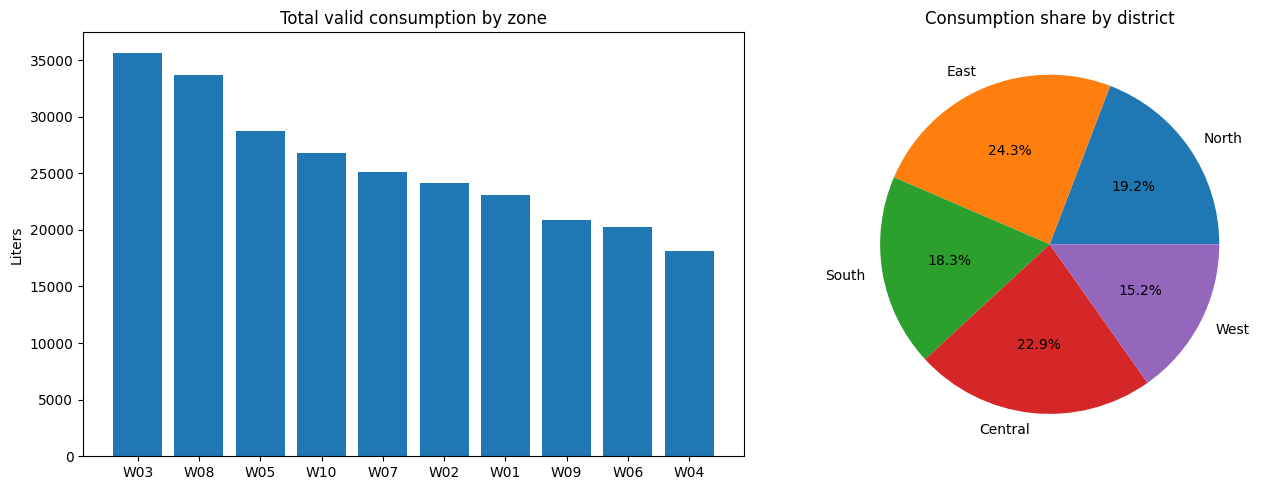

In [0]:
import matplotlib.pyplot as plt
# Q53 bar: total valid consumption by zone ; pie: share by district
zone_df = spark.sql("""
  SELECT z.zone_id, z.zone_name, SUM(r.consumption_liters) AS total
  FROM water_readings_clean r JOIN water_zones z USING (zone_id) GROUP BY 1,2 ORDER BY total DESC""").toPandas()
dist_df = spark.sql("""
  SELECT z.district, SUM(r.consumption_liters) AS total
  FROM water_readings_clean r JOIN water_zones z USING (zone_id) GROUP BY 1""").toPandas()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(zone_df.zone_id, zone_df.total); ax[0].set_title("Total valid consumption by zone"); ax[0].set_ylabel("Liters")
ax[1].pie(dist_df.total, labels=dist_df.district, autopct="%1.1f%%"); ax[1].set_title("Consumption share by district")
plt.tight_layout(); plt.show()

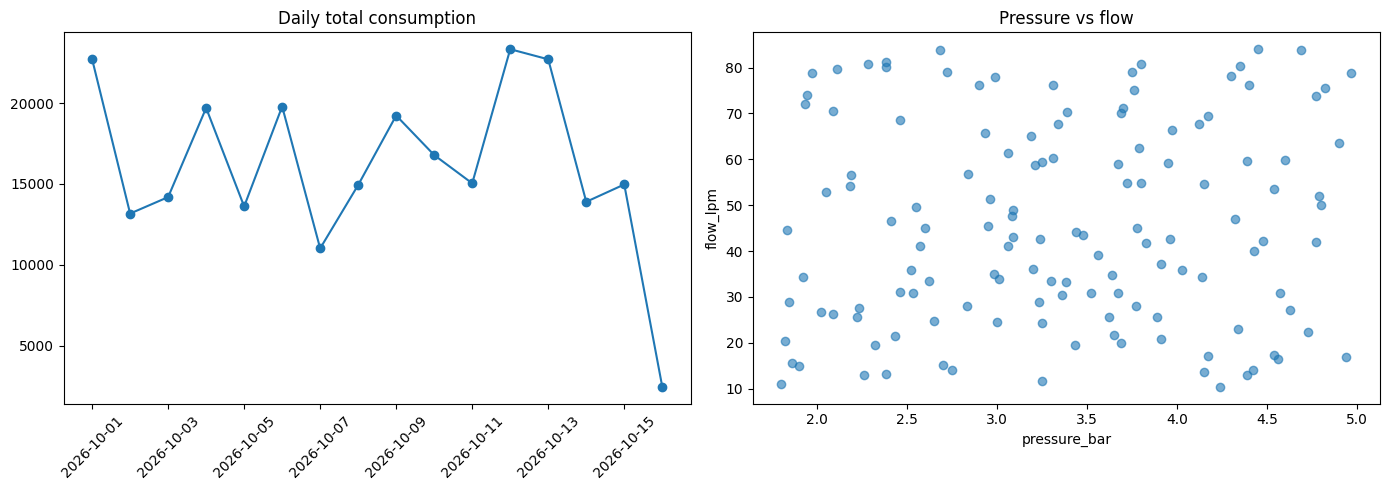

In [0]:
# Q54 line: daily total consumption ; scatter: pressure vs flow (valid)
daily = spark.sql("""SELECT DATE(reading_time) AS day, SUM(consumption_liters) AS total
                     FROM water_readings_clean GROUP BY 1 ORDER BY 1""").toPandas()
sc = spark.sql("SELECT pressure_bar, flow_lpm FROM water_readings_clean").toPandas()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(daily.day, daily.total, marker="o"); ax[0].set_title("Daily total consumption"); ax[0].tick_params(axis="x", rotation=45)
ax[1].scatter(sc.pressure_bar, sc.flow_lpm, alpha=.6); ax[1].set_xlabel("pressure_bar"); ax[1].set_ylabel("flow_lpm"); ax[1].set_title("Pressure vs flow")
plt.tight_layout(); plt.show()

In [0]:
%sql
-- Q55 report: zone consumption + water-quality indicators + service request counts
CREATE OR REPLACE VIEW v_zone_operations_report AS
WITH rd AS (
  SELECT zone_id, SUM(consumption_liters) AS total_consumption, ROUND(AVG(pressure_bar),2) AS avg_pressure,
         SUM(CASE WHEN pressure_bar < 2.5 THEN 1 ELSE 0 END) AS low_pressure_readings,
         ROUND(AVG(chlorine_mg_l),2) AS avg_chlorine,
         SUM(CASE WHEN chlorine_mg_l > 1.0 OR chlorine_mg_l < 0.2 THEN 1 ELSE 0 END) AS chlorine_out_of_band,
         COUNT(*) AS readings
  FROM water_readings_clean GROUP BY zone_id),
rq AS (
  SELECT zone_id, COUNT(*) AS requests,
         SUM(CASE WHEN priority='High' THEN 1 ELSE 0 END) AS high_priority,
         SUM(CASE WHEN issue_type='Low Pressure' THEN 1 ELSE 0 END) AS low_pressure_requests,
         SUM(CASE WHEN issue_type='Water Quality' THEN 1 ELSE 0 END) AS water_quality_requests
  FROM water_service_requests GROUP BY zone_id)
SELECT z.zone_id, z.zone_name, z.district, rd.total_consumption, rd.avg_pressure, rd.low_pressure_readings, rd.readings,
       rd.avg_chlorine, rd.chlorine_out_of_band,
       COALESCE(rq.requests,0) AS requests, COALESCE(rq.high_priority,0) AS high_priority,
       COALESCE(rq.low_pressure_requests,0) AS low_pressure_requests, COALESCE(rq.water_quality_requests,0) AS water_quality_requests
FROM water_zones z LEFT JOIN rd USING (zone_id) LEFT JOIN rq USING (zone_id);
SELECT * FROM v_zone_operations_report ORDER BY low_pressure_readings DESC;

zone_id,zone_name,district,total_consumption,avg_pressure,low_pressure_readings,readings,avg_chlorine,chlorine_out_of_band,requests,high_priority,low_pressure_requests,water_quality_requests
W08,Transit Hub,East,33689,2.87,6,14,0.62,3,4,1,0,0
W03,Market District,Central,35665,3.02,6,13,0.94,6,3,1,0,0
W02,Hill View,North,24120,3.31,5,13,0.62,1,4,2,0,4
W06,Industrial Estate,South,20212,3.16,3,13,0.68,2,4,1,4,0
W01,Old City,Central,23107,3.42,3,13,0.82,4,4,2,4,0
W04,Lake Side,West,18120,3.34,3,13,0.79,4,3,1,0,0
W10,South Extension,South,26788,3.72,2,13,0.8,5,3,1,0,0
W09,Riverfront,West,20894,3.55,1,13,0.68,3,4,1,0,0
W05,University Quarter,East,28717,3.63,0,14,0.87,5,4,1,0,0
W07,Garden Colony,North,25104,3.57,0,13,0.77,4,3,1,0,3


 Two operational findings (from the provided data; chlorine operating band 0.2–1.0 mg/L is an assumption)
1. Unreported low-pressure risk in W08 (Transit Hub) and W03 (Market District): They have the lowest average pressure (2.87 and 3.02 bar) and 6 of ~13-14 clean readings each below 2.5 bar, yet no "Low Pressure" service request exists for either. All 8 Low Pressure tickets sit in W01 and W06 (4 each), whose average pressure is healthy (3.42 / 3.16 bar). Recommend field inspection in W08/W03 and re-checking whether tickets are logged against the right zone.
2. Chlorine over-dosing in W0 : W03 averages 0.94 mg/L with 6 of 13 readings above 1.0 mg/L (highest in the network), and it is also the highest-consumption zone (35,665 L). Combined with only 3 requests and one High priority, it deserves a dosing/water-quality review. W10, W05 and W04 are next (5, 5, 4 readings above 1.0).

*Data-quality note:* W11 has no readings (inactive zone), W99/NULL-zone readings 1154/1156 are orphans, 1044 is duplicated.

Final Capestone

In [0]:
%sql
SELECT 'bronze_readings' AS layer, COUNT(*) AS rows FROM bronze_readings
UNION ALL SELECT 'silver_readings', COUNT(*) FROM silver_readings
UNION ALL SELECT 'gold_zone_summary', COUNT(*) FROM gold_zone_summary

layer,rows
bronze_readings,157
silver_readings,136
gold_zone_summary,10


In [0]:
%sql
SELECT * FROM silver_readings ORDER BY reading_time LIMIT 20

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway
1011,M011,W01,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313,Valid,SmartMeter


In [0]:
%sql
SELECT * FROM gold_zone_summary ORDER BY total_consumption DESC

zone_id,zone_name,district,total_consumption,avg_pressure,avg_chlorine,reading_count
W03,Market District,Central,35665,3.02,0.94,13
W08,Transit Hub,East,33689,2.87,0.62,14
W05,University Quarter,East,28717,3.63,0.87,14
W10,South Extension,South,27808,3.72,0.79,14
W07,Garden Colony,North,25104,3.57,0.77,13
W02,Hill View,North,24120,3.31,0.62,13
W01,Old City,Central,23107,3.42,0.82,13
W09,Riverfront,West,20894,3.55,0.68,13
W04,Lake Side,West,20781,3.24,0.82,14
W06,Industrial Estate,South,20212,3.16,0.68,13


In [0]:
%sql
CREATE OR REPLACE TABLE capstone_readings_work AS
SELECT * FROM water_meter_readings_source WHERE reading_id < 1023

num_affected_rows,num_inserted_rows


In [0]:
%sql
MERGE INTO capstone_readings_work AS t
USING water_reading_changes AS s ON t.reading_id = s.reading_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,1,0,11


In [0]:
%sql
DESCRIBE HISTORY capstone_readings_work

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
3,2026-11-11T11:03:45.000Z,1016212562519381,nabanya04@gmail.com,MERGE,"Map(predicate -> [""(reading_id#52225 = reading_id#52235)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(3984697292656248),f4574cec-a60a-422a-aca1-0bf16ff84031,1111-085325-o1posjke-v2n,2,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 1, executionTimeMs -> 2458, materializeSourceTimeMs -> 1, numTargetRowsInserted -> 11, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 867, numTargetRowsUpdated -> 1, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1557)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T11:02:48.000Z,1016212562519381,nabanya04@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(3984697292656248),4c84107e-fd03-4681-8714-ab80b22d1be3,1111-085325-o1posjke-v2n,1,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 3515, numDeletionVectorsRemoved -> 0, numOutputRows -> 22, numOutputBytes -> 3631)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T11:02:28.000Z,1016212562519381,nabanya04@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(3984697292656248),3543d9f2-f4f6-4683-8174-a446618b8dfe,1111-085325-o1posjke-v2n,0,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 5417, numDeletionVectorsRemoved -> 0, numOutputRows -> 16, numOutputBytes -> 3515)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T11:01:53.000Z,1016212562519381,nabanya04@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(3984697292656248),229a8b20-e398-459d-b829-f3705858a56c,1111-085325-o1posjke-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5417)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
%sql
SELECT 'version 0 (before MERGE)' AS version, reading_id, reading_status, consumption_liters, flow_lpm
FROM capstone_readings_work VERSION AS OF 0 WHERE reading_id = 1005
UNION ALL
SELECT 'current', reading_id, reading_status, consumption_liters, flow_lpm
FROM capstone_readings_work WHERE reading_id = 1005

version,reading_id,reading_status,consumption_liters,flow_lpm
version 0 (before MERGE),1005,Suspect,2656,61.8
current,1005,Valid,2776,64.3


In [0]:
%sql
INSERT INTO water_meter_readings_source
SELECT * FROM water_readings_incremental_staging
WHERE reading_id NOT IN (SELECT reading_id FROM water_meter_readings_source)

num_affected_rows,num_inserted_rows
0,0


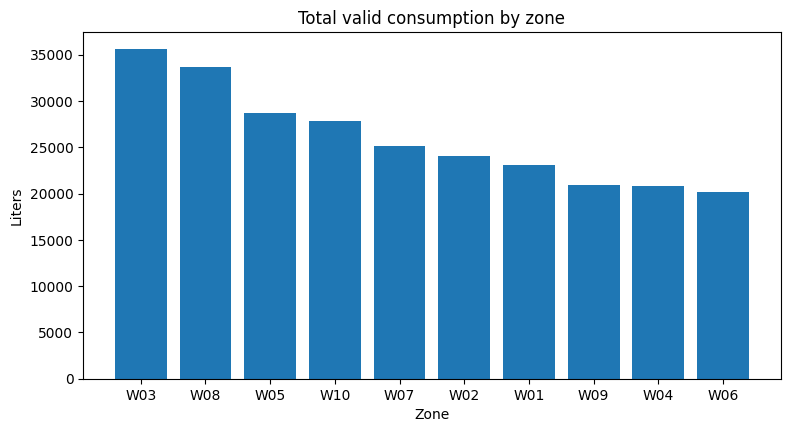

In [0]:
zone_df = spark.table("gold_zone_summary").orderBy(F.desc("total_consumption")).toPandas()
plt.figure(figsize=(9, 4.5)); plt.bar(zone_df.zone_id, zone_df.total_consumption)
plt.title("Total valid consumption by zone"); plt.ylabel("Liters"); plt.xlabel("Zone"); plt.show()

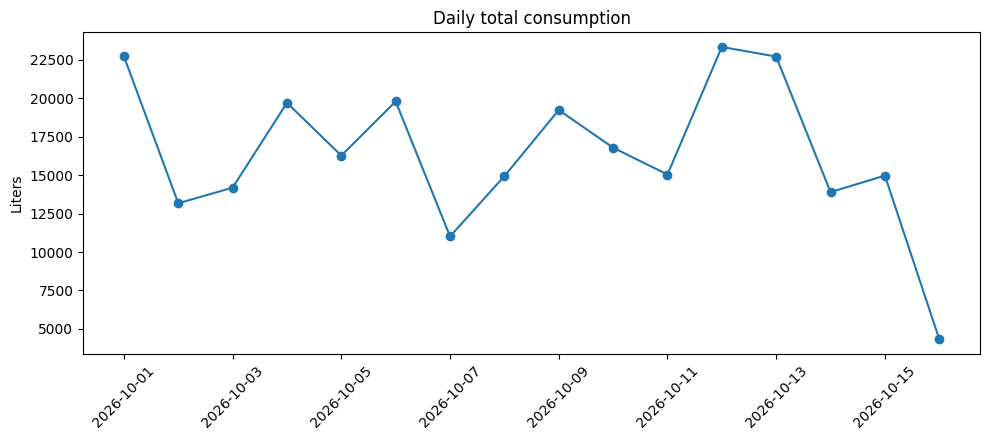

In [0]:
daily = (spark.table("silver_readings").groupBy(F.to_date("reading_time").alias("day"))
         .agg(F.sum("consumption_liters").alias("total")).orderBy("day").toPandas())
plt.figure(figsize=(10, 4.5)); plt.plot(daily.day, daily.total, marker="o")
plt.title("Daily total consumption"); plt.ylabel("Liters"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

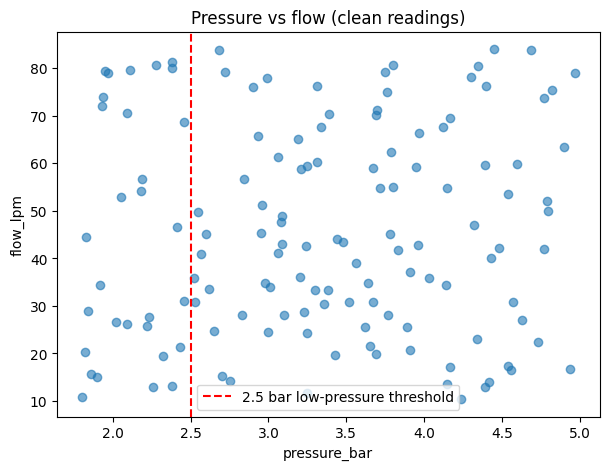

In [0]:
sc = spark.table("silver_readings").select("pressure_bar", "flow_lpm").toPandas()
plt.figure(figsize=(7, 5)); plt.scatter(sc.pressure_bar, sc.flow_lpm, alpha=.6)
plt.axvline(2.5, color="red", linestyle="--", label="2.5 bar low-pressure threshold"); plt.legend()
plt.title("Pressure vs flow (clean readings)"); plt.xlabel("pressure_bar"); plt.ylabel("flow_lpm"); plt.show()